In [ ]:
%load_ext autoreload
%autoreload 2

#%cd ..

c:\Users\coffe\Desktop\titanic-ml\titanic-ml


In [2]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline

from src.preprocessing import build_preprocessor
from src.models import get_model
from src.validation import evaluate_model

SEED = 42

In [3]:
train = pd.read_csv("data/train.csv")

X = train.drop(columns="Survived")
y = train["Survived"]

X.shape, y.shape

((891, 11), (891,))

# lgbm

In [6]:
best_lgbm_params = {
    "learning_rate": 0.022,
    "max_depth": 7,
    "num_leaves": 44,
    "min_child_samples": 21,
    "subsample": 1,
    "colsample_bytree": 0.707,
    "reg_alpha": 0.245,
    "reg_lambda": 0.002,
    "n_estimators": 500,
    "subsample_freq": 1,
}

model = get_model(
    "lightgbm",
    seed=SEED,
    **best_lgbm_params
)

pipeline = Pipeline([
    ("preprocessor", build_preprocessor("boosting")),
    ("model", model),
])

baseline_result = evaluate_model(
    pipeline,
    X,
    y,
    n_splits=5,
    scoring="accuracy",
    seed=SEED,
)

print("Baseline LightGBM")
print("Scores:", baseline_result["scores"])
print("Mean:", baseline_result["mean"])
print("Std:", baseline_result["std"])

Baseline LightGBM
Scores: [0.87150838 0.86516854 0.79213483 0.83707865 0.85393258]
Mean: 0.8439645973259682
Std: 0.028430155662251006


In [8]:
pipeline_family = Pipeline([
    ("preprocessor", build_preprocessor("boosting", use_family_size=True)),
    ("model", model),
])

family_result = evaluate_model(
    pipeline_family,
    X,
    y,
    n_splits=5,
    scoring="accuracy",
    seed=SEED,
)

print("LightGBM + FamilySize")
print("Scores:", family_result["scores"])
print("Mean:", family_result["mean"])
print("Std:", family_result["std"])

LightGBM + FamilySize
Scores: [0.87150838 0.86516854 0.79213483 0.84831461 0.86516854]
Mean: 0.84845897934844
Std: 0.029196315292361094


In [9]:
pipeline_family_alone = Pipeline([
    ("preprocessor", build_preprocessor("boosting", use_family_size=True, use_is_alone=True)),
    ("model", model),
])

family_alone_result = evaluate_model(
    pipeline_family_alone,
    X,
    y,
    n_splits=5,
    scoring="accuracy",
    seed=SEED,
)

print("LightGBM + FamilySize + IsAlone")
print("Scores:", family_alone_result["scores"])
print("Mean:", family_alone_result["mean"])
print("Std:", family_alone_result["std"])

LightGBM + FamilySize + IsAlone
Scores: [0.87150838 0.86516854 0.79775281 0.84831461 0.85955056]
Mean: 0.8484589793484402
Std: 0.02647506002677935


In [10]:
pipeline_family_title = Pipeline([
    ("preprocessor", build_preprocessor("boosting", use_family_size=True, use_is_alone=False, use_title=True)),
    ("model", model),
])

family_title_result = evaluate_model(
    pipeline_family_title,
    X,  
    y,
    n_splits=5,
    scoring="accuracy",
    seed=SEED,
)

print("LightGBM + FamilySize + Title")
print("Scores:", family_title_result["scores"])
print("Mean:", family_title_result["mean"])
print("Std:", family_title_result["std"])

LightGBM + FamilySize + Title
Scores: [0.8603352  0.87078652 0.81460674 0.84269663 0.84269663]
Mean: 0.8462243424769318
Std: 0.0191153278427987


In [13]:
pipeline_family_farelog = Pipeline([
    ('preprocessor', build_preprocessor("boosting", use_family_size=True, use_fare_log=True)),
    ("model", model),
])

family_farelog_result = evaluate_model(
    pipeline_family_farelog,
    X,
    y,
    n_splits=5,
    scoring="accuracy",
    seed=SEED,
)

print("LightGBM + FamilySize + FareLog")
print("Scores:", family_farelog_result["scores"])
print("Mean:", family_farelog_result["mean"])
print("Std:", family_farelog_result["std"])


LightGBM + FamilySize + FareLog
Scores: [0.87150838 0.86516854 0.79213483 0.84831461 0.86516854]
Mean: 0.84845897934844
Std: 0.029196315292361094


In [14]:
pipeline_family_category = Pipeline([
    ('preprocessor',
        build_preprocessor(
            'boosting',
            use_family_size=True,
            use_family_category=True
        ),
    ),
    ('model', model) 
])

family_category_result = evaluate_model(
    pipeline_family_category,
    X,
    y,
    n_splits=5,
    scoring='accuracy',
    seed=SEED,
)

print("LightGBM + FamilySize + Category")
print("Scores:", family_category_result["scores"])
print("Mean:", family_category_result["mean"])
print("Std:", family_category_result["std"])

LightGBM + FamilySize + Category
Scores: [0.86592179 0.85955056 0.76966292 0.84831461 0.85393258]
Mean: 0.8394764923733602
Std: 0.03539307126102478


In [15]:
pipeline_family.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chai

In [16]:
preprocessor = pipeline_family.named_steps["preprocessor"]
lgbm = pipeline_family.named_steps["model"]

In [17]:
feature_names = (
    preprocessor
    .named_steps["columns"]
    .get_feature_names_out()
)

feature_names

array(['num__Age', 'num__Fare', 'num__SibSp', 'num__Parch',
       'num__FamilySize', 'cat__Sex_female', 'cat__Sex_male',
       'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S',
       'cat__Pclass_1', 'cat__Pclass_2', 'cat__Pclass_3',
       'binary__HasCabin'], dtype=object)

In [18]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": lgbm.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

importance_df

,feature,importance
1,num__Fare,3323
0,num__Age,2825
4,num__FamilySize,506
2,num__SibSp,250
5,cat__Sex_female,242
12,cat__Pclass_3,190
9,cat__Embarked_S,189
3,num__Parch,172
7,cat__Embarked_C,168
13,binary__HasCabin,152


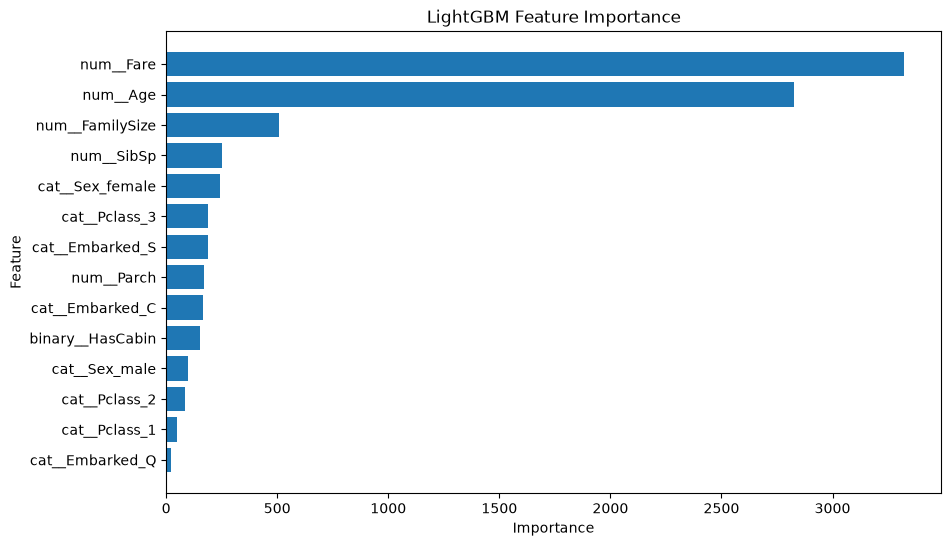

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")

plt.show()

# Catboost

In [23]:
from src.catboost_validation import evaluate_catboost
import inspect

best_catboost_params = {
    "depth": 6,
    "learning_rate": 0.105084,
    "l2_leaf_reg": 2.183935,
    "random_strength": 2.571172,
}

print(inspect.signature(evaluate_catboost))

(X, y, cat_features, model_params=None, n_splits=5, seed=42, early_stopping_rounds=None)


In [24]:
cat_features = ["Sex", "Embarked", "Pclass"]

catboost_baseline = evaluate_catboost(
    X=X,
    y=y,
    cat_features=cat_features,
    model_params=best_catboost_params,
    n_splits=5,
    seed=SEED,
)

print("CatBoost baseline")
print("Scores:", catboost_baseline["scores"])
print("Mean:", catboost_baseline["mean"])
print("Std:", catboost_baseline["std"])

CatBoost baseline
Scores: [0.84357542 0.84269663 0.81460674 0.84831461 0.83146067]
Mean: 0.8361308141359614
Std: 0.012100188250615705


In [25]:
catboost_family = evaluate_catboost(
    X=X,
    y=y,
    cat_features=["Sex", "Embarked", "Pclass"],
    model_params=best_catboost_params,
    n_splits=5,
    seed=SEED,
    use_family_size=True,
)

print("CatBoost + FamilySize")
print("Scores:", catboost_family["scores"])
print("Mean:", catboost_family["mean"])
print("Std:", catboost_family["std"])

CatBoost + FamilySize
Scores: [0.86592179 0.84831461 0.79775281 0.8258427  0.84831461]
Mean: 0.8372293013621241
Std: 0.02348222724084311


In [26]:
catboost_title = evaluate_catboost(
    X=X,
    y=y,
    cat_features=["Sex", "Embarked", "Pclass", "Title"],
    model_params=best_catboost_params,
    n_splits=5,
    seed=SEED,
    use_title=True,
)

print("CatBoost + Title")
print("Scores:", catboost_title["scores"])
print("Mean:", catboost_title["mean"])
print("Std:", catboost_title["std"])

CatBoost + Title
Scores: [0.86592179 0.83707865 0.80898876 0.84831461 0.8258427 ]
Mean: 0.8372293013621241
Std: 0.019356384883451386


In [27]:
catboost_family_title = evaluate_catboost(
    X=X,
    y=y,
    cat_features=["Sex", "Embarked", "Pclass", "Title"],
    model_params=best_catboost_params,
    n_splits=5,
    seed=SEED,
    use_family_size=True,
    use_title=True,
)

print("CatBoost + FamilySize + Title")
print("Scores:", catboost_family_title["scores"])
print("Mean:", catboost_family_title["mean"])
print("Std:", catboost_family_title["std"])

CatBoost + FamilySize + Title
Scores: [0.83240223 0.83146067 0.80898876 0.83707865 0.84269663]
Mean: 0.830525390747599
Std: 0.011483099429012412


# DNN

In [5]:
from src.dnn_validation import evaluate_dnn

dnn_baseline = evaluate_dnn(
    X, 
    y, 
    n_splits=5, 
    epochs=100, 
    batch_size=32, 
    lr=3e-3, 
    seed=SEED
)

print("DNN baseline")
print("Scores:", dnn_baseline["scores"])
print("Mean:", dnn_baseline["mean"])
print("Std:", dnn_baseline["std"])

DNN baseline
Scores: [0.82122904 0.83146065 0.80898875 0.8202247  0.7977528 ]
Mean: 0.8159311890602112
Std: 0.011543978240622206


In [ ]:
from src.dnn_validation import evaluate_dnn

dnn_family = evaluate_dnn(
    X, 
    y, 
    n_splits=5, 
    epochs=100, 
    batch_size=32, 
    lr=3e-3, 
    seed=SEED,
    use_family_size=True
)

print("DNN + FamilySize")
print("Scores:", dnn_family["scores"])
print("Mean:", dnn_family["mean"])
print("Std:", dnn_family["std"])

DNN + FamilySize baseline
Scores: [0.84357542 0.82584268 0.77528089 0.83146065 0.80898875]
Mean: 0.8170296788215637
Std: 0.023656779007647143


In [ ]:
from src.dnn_validation import evaluate_dnn

dnn_fare_log = evaluate_dnn(
    X, 
    y, 
    n_splits=5, 
    epochs=100, 
    batch_size=32, 
    lr=3e-3, 
    seed=SEED,
    use_fare_log=True
)

print("DNN + FareLog")
print("Scores:", dnn_fare_log["scores"])
print("Mean:", dnn_fare_log["mean"])
print("Std:", dnn_fare_log["std"])

DNN + FamilySize baseline
Scores: [0.82122904 0.82584268 0.80337077 0.83707863 0.7977528 ]
Mean: 0.8170547842979431
Std: 0.014528762980904103


In [9]:
from src.dnn_validation import evaluate_dnn

dnn_family_fare_log = evaluate_dnn(
    X, 
    y, 
    n_splits=5, 
    epochs=100, 
    batch_size=32, 
    lr=3e-3, 
    seed=SEED,
    use_family_size=True,
    use_fare_log=True
)

print("DNN + FamilySize + FareLog")
print("Scores:", dnn_family_fare_log["scores"])
print("Mean:", dnn_family_fare_log["mean"])
print("Std:", dnn_family_fare_log["std"])

DNN + FamilySize + FareLog
Scores: [0.84916198 0.84831458 0.80898875 0.84269661 0.82584268]
Mean: 0.8350009202957154
Std: 0.015475912240757343


In [10]:
dnn_family_fare_title = evaluate_dnn(
    X,
    y,
    n_splits=5,
    epochs=100,
    batch_size=32,
    lr=3e-3,
    seed=SEED,
    use_family_size=True,
    use_fare_log=True,
    use_title=True,
)

print("DNN + FamilySize + FareLog + Title")
print("Scores:", dnn_family_fare_title["scores"])
print("Mean:", dnn_family_fare_title["mean"])
print("Std:", dnn_family_fare_title["std"])

DNN + FamilySize + FareLog + Title
Scores: [0.84916198 0.84269661 0.79213482 0.84831458 0.81460673]
Mean: 0.8293829441070557
Std: 0.02250613341749827
